# Amortized Bayesian Inference of the Diffusion Model for Conflict Tasks

Authored by Stefan T. Radev and Simon Schaefer

Large parts of the work below are based on the following paper:
- Schaefer et al., (2026). Amortized Bayesian Workflow for Modeling Congruency Effects Using the Diffusion Model for Conflict Tasks. *Computational Brain & Behavior*. https://link.springer.com/article/10.1007/s42113-026-00266-y

Run cells from top to bottom using the environment described in the repository README. The bundled archive contains the raw trial-level simulations used below, so training does not run the DMC simulator.

## Model Specification

The Diffusion Model for Conflict Tasks (DMC; Ulrich et al., 2015) extends the standard Drift Diffusion Model by including a time-varying drift-rate component. This allows it to explain reaction time distributions and error rates in conflict tasks such as the Stroop, Simon, and Flanker tasks. In these tasks, performance differs between congruent and incongruent trials because relevant and irrelevant stimulus dimensions can either support the same response or interfere with one another. For example, in a flanker task, participants respond to the direction of a central arrow while ignoring the surrounding arrows.

- **Congruent trial** (e.g., → → → → → ): The central target arrow and the flankers all point in the same direction. Because the irrelevant flankers support the same response as the target, responses are usually faster and more accurate.
- **Incongruent trial** (e.g., → → ← → →): The central target arrow points in the opposite direction from the flankers. Here, the irrelevant flankers activate a competing response, which typically leads to slower responses and more errors.

Compared with a stationary DDM-like process, it has been argued that non-stationary processing better captures this conflict process because it can model how the influence of irrelevant information changes over time. As a result, the DMC is assumed to provide a better account of how the congruency effect develops across the reaction time distribution, for example in delta plots.

Similar to a classic DDM, the DMC comprises a constant drift rate $\mu_c$. This route of evidence accumulation, also referred to as the controlled process is driven by the processing of relevant information such as the target stimulus in a flanker paradigm. Simultaneously, a second *automatic* drift process integrates irrelevant information such as the flanker stimuli in the flanker task. A second time-varying drift rate $\mu_a$ reflects this automatic activation at a given point in time $t$ formulated as the derivative of a reshaped gamma function:

$$\mu_a(t) = A \cdot e^{-t/\tau}\cdot \left[ \frac{t\cdot e}{(a-1)\cdot \tau}\right]^{a-1} \cdot \left[\frac{a - 1}{t}-\frac{1}{\tau}\right], a > 1$$

The sign of the amplitude A is defined by the congruency of relevant and irrelevant information. E.g. in a Flanker task, the amplitude is positive if the flankers (irrelevant dimension) are similar to the target (relevant information). Adding up both drift rate $\mu_c$ and $\mu_a$ results in the *superimposed* process, resembling the typically observed congruency effect in RTs and error rates.


![DMC illustration](figures/dmc_illustration.png)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import bayesflow as bf

import dmc_helpers
from dmc_simulator import DMC

rng = np.random.default_rng(2026)
print(f"BayesFlow {bf.__version__}")

INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugin is not implemented on windows yet.
INFO:jax._src.xla_bridge:Unable to initialize backend 'proxy': The 'proxy' backend requires the address of an IFRT Proxy server. Set it via the JAX_BACKEND_TARGET environment variable or the jax_backend_target config option, e.g. JAX_BACKEND_TARGET=grpc://localhost:29000.
INFO:bayesflow:Using backend 'jax'


BayesFlow 2.1.0


In [2]:
param_names = ('A', 'tau', 'mu_c', 'mu_r', 'b', 'sd_r')

simulator = DMC(
    prior_means=np.array([20.49, 118.36, 0.57, 358.01, 61.0, 36.93]),
    prior_sds=np.array([8.4, 37.6, 0.12, 24.27, 13.23, 8.6]), 
    sdr_fixed=None,
    param_names=param_names,
    tmax=1500,
    dt=1,
    rng=rng
)

Note that the maximum decision time is per default set to $1200 ms$ and the time discretization is set to $dt = 1 ms$. Setting $dt$ to lower values will result in a higher temporal resolution while prolonging the simulation time. $t_{max}$ should be chosen so that $\mu_r + t_{max}$ is higher than the maximum RT in the observed data. In order to account for longer RTs, we set  $t_{max}$ to 1500 ms. 

## Training with Raw Data

The archive stores raw parameters, reaction times, choices, and conditions. Summary statistics are computed later in memory.

In [3]:
raw_keys = (*param_names, "rt", "accuracy", "conditions", "num_obs")

with np.load("data/dmc_simulations.npz", allow_pickle=False) as simulations:
    train_data = {key: simulations[f"train_200_{key}"] for key in raw_keys}
    test_data = {key: simulations[f"test_200_{key}"] for key in raw_keys}

**Shape conventions of the cached simulations:**

- **Parameters** (e.g., `"A"`, `"tau"`, ...): shape `(B, 1)` — one scalar per simulated individual.
- **Trial-level data** (`"rt"`, `"accuracy"`, `"conditions"`): shape `(B, N, 1)` — $N$ raw trials per individual.
- **`"num_obs"`**: shape `(B, 1)` — the number of trials in each dataset.

The trailing dimension lets BayesFlow summary networks read each trial as one set element with one feature per variable.

In [4]:
for key, i in train_data.items():
    print(f'{key}: {i.shape}')

A: (1000, 1)
tau: (1000, 1)
mu_c: (1000, 1)
mu_r: (1000, 1)
b: (1000, 1)
sd_r: (1000, 1)
rt: (1000, 200, 1)
accuracy: (1000, 200, 1)
conditions: (1000, 200, 1)
num_obs: (1000, 1)


In conflict tasks, **Conditional Accuracy Functions (CAFs)**, **Cumulative Distribution Functions (CDFs)**, and **delta functions** are commonly used to examine how cognitive control and interference effects unfold across the full reaction time (RT) distribution, rather than being summarized by single mean values. Together, these distributional analyses provide complementary insights into both the speed and accuracy of responses under congruent and incongruent conditions.

- **Conditional Accuracy Functions (CAFs)** characterize how response accuracy varies as a function of response speed. By dividing RTs into quantile-based bins and computing accuracy within each bin, CAFs reveal whether fast responses are more error-prone and whether accuracy improves or deteriorates for slower responses. In conflict tasks, CAFs are particularly informative about early, impulsive response tendencies versus later, more controlled responding, and whether incongruent trials show disproportionate accuracy costs at specific portions of the RT distribution.

- **Cumulative Distribution Functions (CDFs)** describe the overall shape of the RT distribution for each condition. CDFs plot the cumulative probability of responding as a function of RT, allowing direct comparison of how quickly responses are generated under congruent and incongruent conditions. Differences between CDFs indicate global shifts or shape differences in RT distributions, such as whether incongruent trials produce uniformly slower responses or selectively affect only slower portions of the distribution.

- **$\Delta$ - functions** focus explicitly on the difference between congruent and incongruent RT distributions across response speed. Rather than collapsing the congruency effect into a single mean RT difference, delta functions show how this effect changes across quantiles of the RT distribution. This makes it possible to assess whether interference is constant, increases, or decreases as responses become slower, thereby providing insight into the temporal dynamics of conflict processing and control.

**`format_sim_data` and `only_convergents`:** `format_sim_data` converts the dict of arrays returned by the simulator into a tidy `pandas` DataFrame. The simulated diffusion process sometimes fails to reach a decision boundary within $t_{max}$ — these are "non-convergent" trials. `only_convergents=True` excludes them (they'd have an RT of $-1$ or similar sentinel), keeping only trials where a decision was actually made.

**Positive parameter support:** All six DMC parameters have positive priors, so the adapters below learn them in log space. BayesFlow inverts the transform when returning posterior estimates.

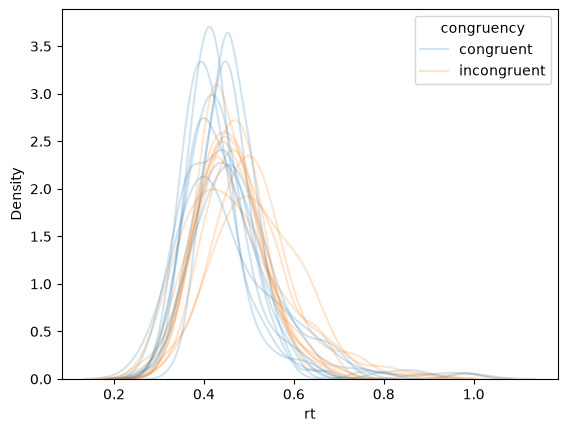

In [5]:
df_complete = dmc_helpers.format_sim_data(test_data, only_convergents=True)

for individual_id in range(10):

    # select data from individual id
    df_id = df_complete[df_complete['id'] == individual_id]

    # plot rt distribution excluding values of -1
    sns.kdeplot(df_id, x='rt', hue='congruency', alpha=0.2)

In [6]:
workflow = bf.BasicWorkflow(
    inference_network=bf.networks.CouplingFlow(),
    summary_network=bf.networks.SetTransformer(embed_dims=(16, 16), summary_dim=32),
    adapter=(
        bf.Adapter()
        .log(param_names)
        .concatenate(param_names, into="inference_variables")
        .concatenate(["rt", "conditions", "accuracy"], into="summary_variables")
    ),
    standardize="all"
)

In [ ]:
history = workflow.fit_offline(
    train_data, batch_size=16, epochs=15, validation_data=test_data
)

In [ ]:
samples = workflow.sample(conditions=test_data, num_samples=1000)

In [ ]:
figs = workflow.plot_default_diagnostics(
    test_data=test_data, 
    samples=samples
)

In [ ]:
metrics = workflow.compute_default_diagnostics(test_data=test_data, samples=samples)
metrics

## Training with Informative Summary Statistics

**Key details in `summary_stats`:**

- **`[..., 0]`** strips the trailing dimension: `(B, N, 1)` → `(B, N)`, since each variable is stored as a single-column "feature".
- **Masking with `np.where`:** `np.where(mask, rt, np.nan)` keeps RTs where the mask is `True` and fills the rest with `NaN`. `np.nanquantile` then computes quantiles while ignoring `NaN`s — this avoids explicitly indexing ragged groups per batch.
- **`stats[np.isnan(stats)] = -1.`:** If a group is empty (e.g., no errors for a given condition in a batch), `nanquantile` returns `NaN`. Replacing with $-1$ provides a sentinel value the network can learn to ignore, since RTs are always positive.
- **`**kwargs`:** Absorbs extra dict keys (e.g., `"A"`, `"tau"`, `"num_obs"`, ...) that are present in the data dict but not needed here. This makes the function compatible with `summary_stats(**train_data)`.

In [ ]:
def summary_stats(conditions, rt, accuracy, num_quantiles=5, **kwargs):
    """Computes hand-crafted summary statistics to be used on batched conditions, 
    rts, and accuracies.
    """

    quantiles = np.linspace(0.05, 0.95, num_quantiles)
    rt        = rt[..., 0]
    conditions = conditions[..., 0]
    accuracy   = accuracy[..., 0]

    valid = np.isfinite(rt) & (rt > 0) & np.isin(accuracy, (0, 1))
    quantile_parts = []
    for cond_val in (0, 1):
        for acc_val in (0, 1):
            mask = (conditions == cond_val) & (accuracy == acc_val) & valid
            q = np.nanquantile(np.where(mask, rt, np.nan), quantiles, axis=1).T
            quantile_parts.append(q)

        
    acc_c0 = np.nanmean(np.where((conditions == 0) & valid, accuracy, np.nan), axis=1, keepdims=True)
    acc_c1 = np.nanmean(np.where((conditions == 1) & valid, accuracy, np.nan), axis=1, keepdims=True)

    stats = np.concatenate([*quantile_parts, acc_c0, acc_c1], axis=1)

    stats[np.isnan(stats)] = -1.

    return {"summary_stats": stats}

**The `|=` (merge-update) pattern:** `train_data |= summary_stats(**train_data)` unpacks the entire data dict as keyword arguments to `summary_stats`. The function ignores unneeded keys via `**kwargs` and returns `{"summary_stats": ...}`. The `|=` operator merges this back into the original dict, adding the new `"summary_stats"` key alongside the existing `"rt"`, `"conditions"`, etc.

In [ ]:
train_data |= summary_stats(**train_data)
test_data |= summary_stats(**test_data)

**Why no `summary_network` anymore?** 

In the first workflow above, raw trial-level data (`rt`, `conditions`, `accuracy`) was passed as `summary_variables` and a `SetTransformer` learned to compress them into a fixed-size representation. Here, we instead pre-compute hand-crafted summary statistics and pass them via `inference_conditions`. This means the inference network receives a fixed `(B, 22)` vector directly. No learnable summary network is needed. This can be more interpretable and sometimes more data-efficient, but it requires domain knowledge to design good summaries.

In [ ]:
workflow = bf.BasicWorkflow(
    inference_network=bf.networks.CouplingFlow(),
    adapter=(
        bf.Adapter()
        .log(param_names)
        .concatenate(param_names, into="inference_variables")
        .concatenate("summary_stats", into="inference_conditions")
    ),
    standardize="all",
)

In [ ]:
history = workflow.fit_offline(
    train_data, epochs=50, batch_size=32, validation_data=test_data
)

In [ ]:
samples = workflow.sample(conditions=test_data, num_samples=1000)

In [ ]:
figs = workflow.plot_default_diagnostics(test_data, samples=samples)

## Comparing Posterior Estimators

We first compare flow matching and a coupling flow, then train an ensemble containing flow matching and a diffusion model. These neural diffusion models approximate posterior distributions; the cognitive DMC simulator above describes decision making.

### Separate Workflows

In [ ]:
workflows = {}
estimators = {
    "fm": bf.networks.FlowMatching(subnet_kwargs={"widths": (128,)*3}),
    "cf": bf.networks.CouplingFlow()
}
histories = {}

for name, estimator in estimators.items():

    workflow = bf.BasicWorkflow(
        inference_network=estimator,
        adapter=(
            bf.Adapter()
            .log(param_names)
            .concatenate(param_names, into="inference_variables")
            .concatenate("summary_stats", into="inference_conditions")
        ),
        standardize="all",
    )

    history = workflow.fit_offline(
        train_data, epochs=50, batch_size=32, validation_data=test_data
    )

    workflows[name] = workflow
    histories[name] = history

In [ ]:
figs = workflows["fm"].plot_default_diagnostics(
    test_data=test_data,
    num_samples=300,
)

In [ ]:
figs = workflows["cf"].plot_default_diagnostics(
    test_data=test_data,
    num_samples=300,
)

### Using Deep Ensembles

**`EnsembleWorkflow`** trains multiple inference networks jointly on the same data. Each member learns a different posterior approximation, and their samples can be merged for better coverage.

In [ ]:
workflow = bf.EnsembleWorkflow(
    inference_networks={
        "fm": bf.networks.FlowMatching(subnet_kwargs={"widths": (64,)*3}),
        "dm": bf.networks.DiffusionModel(subnet_kwargs={"widths": (64,)*3}),
    },
    adapter=(
        bf.Adapter()
        .log(param_names)
        .concatenate(param_names, into="inference_variables")
        .concatenate("summary_stats", into="inference_conditions")
    ),
    standardize="all"
)

history = workflow.fit_offline(
    train_data, batch_size=32, epochs=100, validation_data=test_data
)

In [ ]:
# Obtain posterior draws from all ensemble members
marginal_draws = workflow.sample(
    conditions=test_data,
    batch_size=25,
    num_samples=300,
    merge_members=False
)

**Why `merge_members=False`?** By default, `EnsembleWorkflow.sample()` pools draws from all members into a single sample. Setting `merge_members=False` returns a dict keyed by member name, so we can inspect each member's recovery performance individually and diagnose which estimator contributes most (or poorly).

In [ ]:
for member, samples in marginal_draws.items():
    f = bf.diagnostics.recovery(samples, test_data, variable_names=param_names)
    f.suptitle(f"Recovery - Ensemble Member {member.upper()}")

## Adding Point Estimators to the mix

In [ ]:
workflow = bf.EnsembleWorkflow(
    inference_networks={
        "fm": bf.networks.FlowMatching(subnet_kwargs={"widths": (128,)*3}),
        "dm": bf.networks.DiffusionModel(subnet_kwargs={"widths": (128,)*3}),
        "qt": bf.networks.ScoringRuleNetwork(
            quantiles=bf.scoring_rules.QuantileScore(np.linspace(0.1, 0.9, 5)),
        )
    },
    adapter=(
        bf.Adapter()
        .log(param_names)
        .concatenate(param_names, into="inference_variables")
        .concatenate("summary_stats", into="inference_conditions")
    ),
    standardize="all"
)

history = workflow.fit_offline(
    train_data, batch_size=32, epochs=200, validation_data=test_data
)

In [ ]:
# Obtain posterior draws from all ensemble members
marginal_draws = workflow.sample(
    conditions=test_data,
    batch_size=50,
    num_samples=300,
    merge_members=False
)

In [ ]:
# Only plot recovery
for member, samples in marginal_draws.items():
    f = bf.diagnostics.recovery(samples, test_data, variable_names=param_names)
    f.suptitle(f"Recovery - Ensemble Member {member.upper()}")

In [ ]:
# Optional exercise: repeat the calibration check for each posterior estimator.
# Quantile estimates are inspected separately in the following cell.
for member, member_samples in marginal_draws.items():
    fig = bf.diagnostics.calibration_ecdf(
        member_samples, test_data, variable_names=param_names
    )
    fig.suptitle(f"Calibration - Ensemble Member {member.upper()}")

In [ ]:
marker_mapping = dict(quantiles="_")

estimates = workflow.estimate(conditions=test_data)

f = bf.diagnostics.recovery_from_estimates(estimates["qt"], test_data, variable_names=param_names, marker_mapping=marker_mapping)

## Fitting Real Data

The empirical flanker-task data are bundled in `data/experiment_data_narrow.csv`; no download is needed. We account for varying numbers of retained trials, fit the posterior estimator, and compare observed and posterior-predictive behavior.

### Data Considerations

In [ ]:
data = pd.read_csv("dmc/data/experiment_data_narrow.csv")

In [ ]:
data = (data[['participant', 'rt', 'accuracy', 'congruency_num']]
        .rename(columns={'congruency_num': "congruency"})
)

In [ ]:
data.head()

Determine the proportion of missing values.

In [ ]:
num_trials = data.groupby("participant").size().values

print("Mean retained trial proportion:", (num_trials / 400).mean())
print("Std. of retained trial proportion:", (num_trials / 400).std())

**Subsampling for training robustness:** Real participants have missing or excluded trials. During training, we randomly retain about 86% of trials and append the retained proportion as a 23rd summary feature. Observed participants use all valid trials and their actual retained proportion.

In [ ]:
def _trial_arrays(conditions, rt, accuracy):
    rt = rt[..., 0]
    conditions = conditions[..., 0]
    accuracy = accuracy[..., 0]
    valid = np.isfinite(rt) & (rt > 0) & np.isin(accuracy, (0, 1))
    return conditions, rt, accuracy, valid


def _retained_summary_stats(conditions, rt, accuracy, keep, props, num_quantiles=5):
    quantiles = np.linspace(0.05, 0.95, num_quantiles)
    quantile_parts = []
    for cond_val in (0, 1):
        for acc_val in (0, 1):
            mask = (conditions == cond_val) & (accuracy == acc_val) & keep
            q = np.nanquantile(np.where(mask, rt, np.nan), quantiles, axis=1).T
            quantile_parts.append(q)

    acc_c0 = np.nanmean(
        np.where((conditions == 0) & keep, accuracy, np.nan), axis=1, keepdims=True
    )
    acc_c1 = np.nanmean(
        np.where((conditions == 1) & keep, accuracy, np.nan), axis=1, keepdims=True
    )
    stats = np.concatenate([*quantile_parts, acc_c0, acc_c1, props], axis=1)
    stats[np.isnan(stats)] = -1.0
    return {"summary_stats": stats}


def summary_stats_subsample(conditions, rt, accuracy, rng, **kwargs):
    conditions, rt, accuracy, valid = _trial_arrays(conditions, rt, accuracy)
    keep = (rng.random(rt.shape) < 0.86) & valid
    props = keep.mean(axis=1, keepdims=True)
    return _retained_summary_stats(conditions, rt, accuracy, keep, props)


def summary_stats_observed(conditions, rt, accuracy, props, **kwargs):
    conditions, rt, accuracy, valid = _trial_arrays(conditions, rt, accuracy)
    props = np.broadcast_to(np.asarray(props).reshape(-1, 1), (rt.shape[0], 1))
    return _retained_summary_stats(conditions, rt, accuracy, valid, props)

In [ ]:
with np.load("dmc/data/dmc_simulations.npz", allow_pickle=False) as simulations:
    train_data = {key: simulations[f"train_400_{key}"] for key in raw_keys}
    test_data = {key: simulations[f"test_400_{key}"] for key in raw_keys}

In [ ]:
train_data |= summary_stats_subsample(**train_data, rng=rng)
test_data |= summary_stats_subsample(**test_data, rng=rng)

In [ ]:
test_data["summary_stats"][:, -1]

### Training and In-Silico Diagnostics

Below, we use the hyperparameters determined via Optuna.

In [ ]:
batch_size = 32
depth = 3
width = 128
initial_lr = 5e-4

workflow = bf.BasicWorkflow(
    inference_network=bf.networks.FlowMatching(subnet_kwargs={"widths": (width,)*depth}),
    adapter=(
        bf.Adapter()
        .log(param_names)
        .concatenate(param_names, into="inference_variables")
        .concatenate("summary_stats", into="inference_conditions")
    ),
    initial_learning_rate=initial_lr,
    standardize="all"
)

history = workflow.fit_offline(
    train_data, batch_size=batch_size, epochs=100, validation_data=test_data
)

In [ ]:
figs = workflow.plot_default_diagnostics(test_data=test_data, num_samples=500)

**Why loop over participants?**

The trained network expects a 23-value summary vector. Each participant has a different number of retained trials, so we compute one vector at a time and include the fraction of the original 400 trials.

In [ ]:
conditions = []
participant_ids = np.unique(data.participant).tolist()

for participant_id in participant_ids:

    participant_df = data[data["participant"] == participant_id]

    participant_dict = {
        "rt": participant_df["rt"].values[None, :, None],
        "accuracy": participant_df["accuracy"].values[None, :, None],
        "conditions": participant_df["congruency"].values[None, :, None],
        "props": np.array([[len(participant_df) / 400]])
    }

    conditions.append(summary_stats_observed(**participant_dict)["summary_stats"])

conditions = np.concatenate(conditions, axis=0)

In [ ]:
samples = workflow.sample(
    conditions={"summary_stats": conditions}, num_samples=500, batch_size=10
)

**Posterior Predictive Check:** For each participant, we take 10 posterior draws, simulate 400 trials from each, and compare the resulting CAFs, CDFs, and $\Delta$-functions with the observed data.

In [ ]:
sample_idx = rng.permutation(500)[:10]
rows = []

for p_idx, p in enumerate(participant_ids):
    for draw_idx, s_idx in enumerate(sample_idx):
        sample = {key: value[p_idx, s_idx, 0] for key, value in samples.items()}
        resim = simulator.experiment(**sample, num_obs=400, rng=rng)

        part_df = pd.DataFrame(resim)
        part_df["id"] = p
        part_df["draw_idx"] = draw_idx

        rows.append(part_df)

df_long = pd.concat(rows, ignore_index=True)
# The simulator encodes trials without a boundary crossing with accuracy = -1.
df_long = df_long.loc[(df_long["rt"] > 0) & df_long["accuracy"].isin([0, 1])].copy()

In [ ]:
df_long.head()

In [ ]:
caf, cdf, delta = dmc_helpers.compute_stats(df_long, id_name='id', rt='rt', congruency='conditions')

In [ ]:
empirical_subset = data[data["participant"].isin(participant_ids)]
caf_emp, cdf_emp, delta_emp = dmc_helpers.compute_stats(
    empirical_subset, id_name="participant", congruency="congruency"
)
fig, axes = dmc_helpers.plot_fit(
    caf, cdf, delta, caf_emp, cdf_emp, delta_emp,
    congruency="conditions", congruency_emp="congruency"
)
fig.suptitle("Posterior predictive (solid) and observed (dashed) behavior", y=1.05)